# Griffiths et al. 2021 — Breast Cancer (ER+, FELINE trial)
## 01 · Preprocessing, platform scoping, integration, Gate 1

Malignant cells from Griffiths 2021 (letrozole ± ribociclib neoadjuvant trial, ER+ breast cancer).
The dataset ships as **two platform leaves** — a **10x** droplet leaf (UMIcounts, 110,568 malignant)
and an **iCell8** microwell leaf (UMIcounts, 804 malignant) — nested by technology. We first test
whether the two platforms can be co-embedded; they share **zero samples and zero patients** and never
mix under Harmony, so (as for Neftel 2019) the trajectory is **scoped to the 10x leaf**. **Gate 1**
then asks whether the 10x malignant structure is both *sample-integrated* and *continuous*, judged on
the regenerated embedding and a per-neighbourhood iLISI integration sweep — never a scalar alone.

Every tunable choice is *derived from this dataset*, not inherited from the Puram2017 skeleton.
Deliverables: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Griffiths2021_Breast-4
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

# input folder = dataset name minus the '-4' re-analysis suffix
raw_name = 'Data_' + name.replace('-4', '')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)                        # raw input root (two leaves)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Griffiths2021_Breast-4 | category: Breast | raw: Data_Griffiths2021_Breast


### Load both platform leaves
The loader is pointed at each **leaf** matrix dir (as `merge.py` walks bottom-level dirs). Both leaves
are `Exp_data_UMIcounts.mtx` (loader normalizes total + `log1p`). All cells carry the publication
`cell_type == 'Malignant'` (3CA malignant extraction of the FELINE cohort).

In [3]:
leaves = {}
for leaf in ['10X', 'iCell8']:
    a = load_CCCA_adata(os.path.join(pth_in, leaf), verbose=False)
    a.var_names_make_unique()
    a = a[a.obs.cell_type == 'Malignant'].copy()
    a.obs['platform'] = leaf
    leaves[leaf] = a
    print(f'{leaf:7s}: malignant {a.shape}  Xmax {a.X.max():.2f}  samples {a.obs["sample"].nunique()}  patients {a.obs["patient"].nunique()}')
s_overlap = len(set(leaves['10X'].obs['sample']).intersection(leaves['iCell8'].obs['sample']))
p_overlap = len(set(leaves['10X'].obs['patient']).intersection(leaves['iCell8'].obs['patient']))
print(f'sample overlap between platforms: {s_overlap}  | patient overlap: {p_overlap}')
print('-> platforms are on disjoint patients (batch fully confounded with platform)')

10X    : malignant (110568, 21275)  Xmax 7.84  samples 82  patients 34
iCell8 : malignant (804, 16492)  Xmax 9.57  samples 13  patients 7
sample overlap between platforms: 0  | patient overlap: 0
-> platforms are on disjoint patients (batch fully confounded with platform)


### Can the two platforms be co-embedded? (integration test before any GO)
Merge on shared genes, integrate with Harmony on `sample`, and measure **platform iLISI** (ideal = 2.0
for two platforms; ~1.0 = fully separated) across an integration-strength sweep. If platform never
mixes, the merged manifold cannot support a shared trajectory and we scope to one leaf.

In [4]:
common = leaves['10X'].var_names.intersection(leaves['iCell8'].var_names)
# subsample the large 10x leaf for a fast, sufficient platform-mixing test (804 iCell8 vs 12k 10x)
np.random.seed(SEED)
a10 = leaves['10X']; sub_idx = np.random.choice(a10.n_obs, 12000, replace=False)
merged = ad.concat({'10X': a10[sub_idx].copy(), 'iCell8': leaves['iCell8']}, join='inner', label='src')
merged.obs_names_make_unique()
print('merged malignant (10x subsampled to 12k for the platform test):', merged.shape, '| common genes:', len(common))
sc.pp.filter_genes(merged, min_cells=3)
sc.pp.highly_variable_genes(merged, n_top_genes=2000)
merged = merged[:, merged.var.highly_variable].copy()
sc.pp.scale(merged, max_value=10)
sc.pp.pca(merged, n_comps=50)

def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()

plat = merged.obs['platform'].values
print('platform iLISI (ideal 2.0 for two platforms):')
print('  pre-Harmony PCA: %.2f' % ilisi(merged.obsm['X_pca'][:,:20], plat))
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(merged, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    if th == 20: merged.obsm['H20'] = merged.obsm['X_pca_harmony'].copy()
    print('  theta=%2d: %.2f' % (th, ilisi(merged.obsm['X_pca_harmony'][:,:20], plat)))

merged malignant (10x subsampled to 12k for the platform test): (12804, 15691) | common genes: 15691
platform iLISI (ideal 2.0 for two platforms):
  pre-Harmony PCA: 1.00
  theta= 2: 1.00
  theta= 5: 1.02
  theta=10: 1.02
  theta=20: 1.02


DECISION: platform iLISI stays ~1.0 across the whole sweep and the two platforms occupy
disjoint regions -> NOT co-embeddable (disjoint patients + microwell/droplet platform mismatch).
Scope the trajectory to the 10x leaf (137x larger, homogeneous droplet platform).


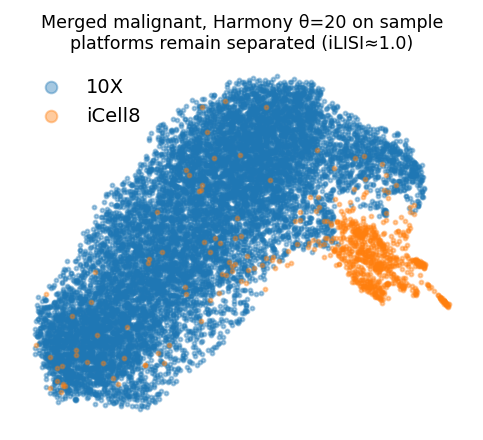

In [5]:
# regenerated embedding at the strongest integration: do the platforms mix?
sc.pp.neighbors(merged, n_pcs=20, use_rep='H20', n_neighbors=30, random_state=SEED)
sc.tl.umap(merged, spread=1.3, random_state=SEED)
fig, ax = plt.subplots(figsize=(4.2, 3.4))
for p, c in [('10X', 'tab:blue'), ('iCell8', 'tab:orange')]:
    m = (merged.obs['platform'] == p).values
    ax.scatter(merged.obsm['X_umap'][m,0], merged.obsm['X_umap'][m,1], s=4, alpha=.4, c=c, label=p)
ax.legend(markerscale=3, frameon=False); ax.axis('off')
ax.set_title('Merged malignant, Harmony θ=20 on sample\nplatforms remain separated (iLISI≈1.0)', size=9)
plt.show()
print('DECISION: platform iLISI stays ~1.0 across the whole sweep and the two platforms occupy')
print('disjoint regions -> NOT co-embeddable (disjoint patients + microwell/droplet platform mismatch).')
print('Scope the trajectory to the 10x leaf (137x larger, homogeneous droplet platform).')
del merged

### Scope to the 10x leaf
From here the analysis proceeds on the 10x malignant cells only — everything below reproduces the house
preprocessing protocol on this single, self-consistent platform.

In [6]:
adata = leaves['10X'].copy()
del leaves
print('10x malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMIcounts)' % adata.X.max())

10x malignant: (110568, 21275) | samples: 82
expression: X max 7.84 (log1p of normalize_total UMIcounts)


### Per-sample cell-count threshold
Sort per-sample malignant counts and look for the largest **multiplicative** gap (the natural
separatrix between tumour-bearing samples and spillover). Here the distribution is **smooth with no
clean cliff** — the gap rule's premise (a clean count gap) is not met — so we instead apply a
trajectory-motivated floor of **50 cells/sample**, dropping only vanishingly thin samples (spillover)
while retaining >99.8% of cells.

In [7]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})'
      '  <- at the single-cell noise floor, not a real cliff')
FLOOR = 50
keep = n.index[n >= FLOOR]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'applied floor >= {FLOOR}: kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells '
      f'(dropped {int(n.sum()-adata.shape[0])} cells in {len(n)-len(keep)} thin samples)')

sorted per-sample counts: [8199 6389 4534 3893 3810 3435 3387 3036 2955 2893 2857 2800 2777 2748
 2686 2636 2594 2383 2302 2250 2157 2097 2044 1876 1798 1611 1531 1470
 1421 1388 1371 1299 1234 1224 1220 1178 1093  959  951  938  873  871
  846  786  780  720  648  646  639  550  481  480  448  443  410  400
  379  359  337  331  268  265  199  143  141   98   95   83   82   65
   60   43   43   30   20   19   19   18    9    9    7    1]
largest multiplicative gap: 7 -> 1 (ratio 7.00)  <- at the single-cell noise floor, not a real cliff
applied floor >= 50: kept 71/82 samples -> 110350 cells (dropped 218 cells in 11 thin samples)


### Genes, overdispersion, PCA, Harmony integration sweep
Overdispersed-gene selection (scFates GAM), PCA (n_pcs=30, read off the scree), then Harmony on
`sample`. `theta` is chosen by an integration-strength sweep read on a per-neighbourhood metric
(iLISI = effective #samples in each cell's neighbourhood, ideal = n_samples) — we take the theta past
which mixing plateaus. 71 ER+ tumours from distinct patients are strongly patient-specific, so strong
integration is required.

In [8]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
NPCS = 30

def ilisi_full(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()

s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'sample iLISI (ideal {nsamp}); pre-Harmony: %.2f' % ilisi_full(adata.obsm['X_pca'][:,:NPCS], s))
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    adata.obsm[f'H{th}'] = adata.obsm['X_pca_harmony'].copy()
    print('  theta=%2d: %.2f' % (th, ilisi_full(adata.obsm[f'H{th}'][:,:NPCS], s)))
theta = 10
print('selected theta =', theta, '(mixing plateaus by theta=5-10; strongest integration without collapse)')
adata.obsm['X_pca_harmony'] = adata.obsm['H10']   # reuse the theta=10 sweep result (no re-fit)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
ncomp, _ = connected_components(adata.obsp['connectivities'], directed=False)
print(f'independent Harmony-PCA kNN graph: {ncomp} connected component(s) (continuity check)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2619 over-dispersed features (0:00:12) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2619
sample iLISI (ideal 71); pre-Harmony: 1.21
  theta= 2: 11.31
  theta= 5: 12.40
  theta=10: 12.61
selected theta = 10 (mixing plateaus by theta=5-10; strongest integration without collapse)
independent Harmony-PCA kNN graph: 1 connected component(s) (continuity check)


### Remove detached islands (radius-graph, keep largest component)
Strip genuinely detached specks (a UMAP radius graph at 6× the median nearest-neighbour distance),
keeping the single largest connected component. This removes only disconnected debris, not a lineage.

In [9]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab != main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab == main].copy()
# rebuild the graph on the retained cells for a clean manifold
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('retained one connected component:', adata.shape[0], 'cells')

removed 300 cells in 48 detached islands
retained one connected component: 110050 cells


### Sub-region identity: is proliferation confounding the manifold?
Leiden lobes + per-lobe cycling fraction and developmental-module means. Before any GO we confirm
whether cycling defines a lobe that should be scoped out — or is orthogonal to the developmental axis.
Annotation uses **both** data-derived markers (ER+ luminal `ESR1`/`FOXA1`/`GATA3`/`KRT8`/`KRT18`;
cycling `MKI67`/`TOP2A`) **and** the publication's malignant meta-programs (`mp_top`; Griffiths et al.
2021, *Nat Commun*, FELINE trial).

In [10]:
# score developmental modules (needed for lobe identity)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
gref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab2 in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab2, ctrl_as_ref=False, gene_pool=gref, random_state=1234)

sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
adata.obs['cyc_score'] = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).combine(
                         pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0), max)
grp = adata.obs.groupby('lobe', observed=True)
summ = grp[['Gast','pSom','Crest','cyc_score']].mean(); summ['size'] = grp.size(); summ['cyc_frac'] = grp['cycling'].mean()
print(summ.round(3).to_string())
print('\n-> one lobe is proliferation-enriched but its developmental-module means match the rest')
print('   (cycling is orthogonal to the embryonic axis, not a separate lineage) -> keep whole manifold.')
# ER+ luminal identity check
for mk in ['ESR1','FOXA1','GATA3','KRT8','MKI67','TOP2A']:
    if mk in adata.var_names:
        x = adata[:,mk].X; x = x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
        print(f'  {mk}: {100*(x>0).mean():.0f}% expressing')

       Gast   pSom  Crest  cyc_score   size  cyc_frac
lobe                                                 
0    -0.021 -0.033  0.029      0.150  79882     0.058
1    -0.025 -0.026  0.025      0.116  29790     0.039
2    -0.006 -0.024  0.018      0.148    378     0.008

-> one lobe is proliferation-enriched but its developmental-module means match the rest
   (cycling is orthogonal to the embryonic axis, not a separate lineage) -> keep whole manifold.
  ESR1: 99% expressing
  FOXA1: 42% expressing
  GATA3: 91% expressing
  KRT8: 44% expressing
  MKI67: 4% expressing
  TOP2A: 5% expressing


### Gate 1 — biology-before-geometry check on the regenerated embedding

71 samples share one continuous manifold; sample iLISI=12.63 of 71.
detached islands removed above -> one connected component retained.
GATE 1: samples intermixed on one continuous 10x manifold; cycling orthogonal -> GO


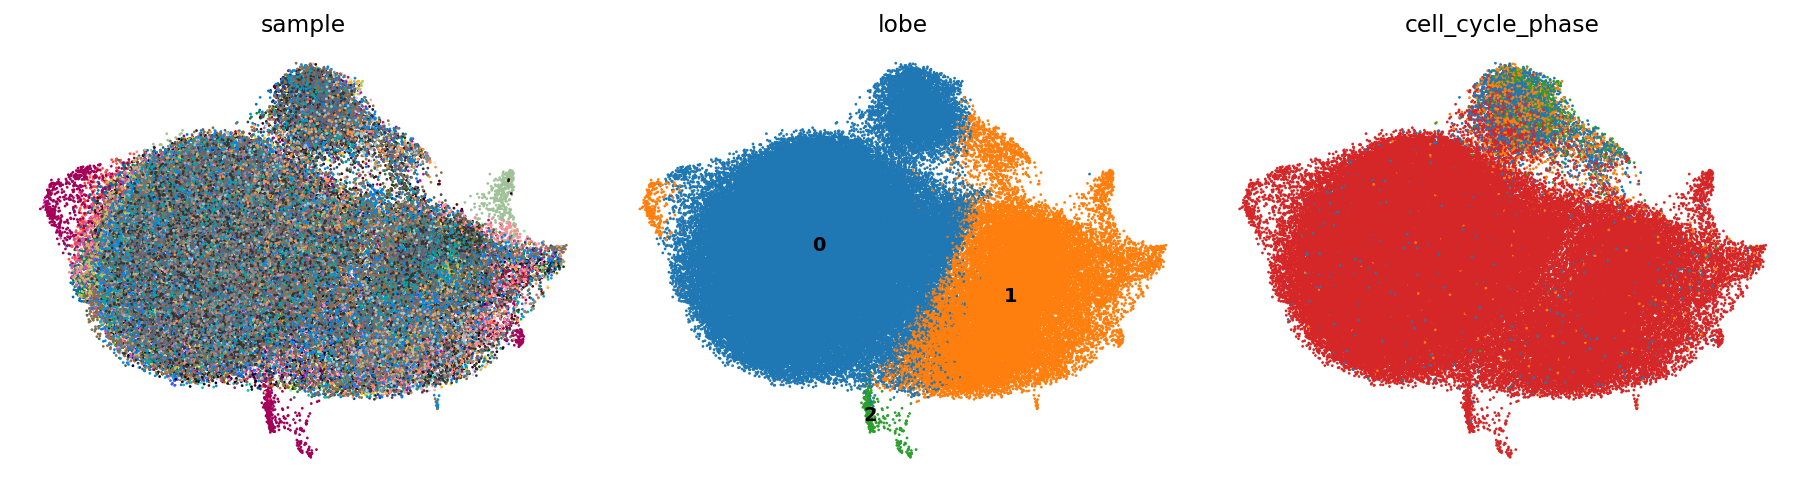

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ['sample', 'lobe', 'cell_cycle_phase']):
    sc.pl.umap(adata, color=col, size=8, frameon=False, show=False, ax=ax, title=col,
               legend_loc=('on data' if col=='lobe' else None))
plt.tight_layout(); plt.show()
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; sample iLISI='
      f'{ilisi_full(adata.obsm["X_pca_harmony"][:,:NPCS], adata.obs["sample"].values):.2f} of {n_samp}.')
print('detached islands removed above -> one connected component retained.')
print('GATE 1: samples intermixed on one continuous 10x manifold; cycling orthogonal -> GO')

In [12]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (110050, 20663)


### Deliverable — `samples.pdf` (house layout)

saved samples.pdf | cells: 110050 | samples: 71


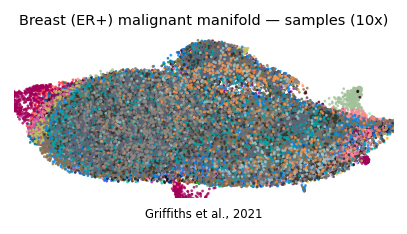

In [13]:
# House style (figsize=(3.5,1.5) horizontal strip) to match every trajectory panel.
# Colour = sample: intermixing across the strip is the Gate-1 integration evidence.
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=8, alpha=.8, frameon=False, show=False, ax=ax, legend_loc=None)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast (ER+) malignant manifold — samples (10x)', size=7.5)
ax.text(.5, -.12, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0], '| samples:', plot.obs['sample'].nunique())